# Práctica de laboratorio: comparar modelos de clasificación

**Problema:** clasificar cada defunción como **fetal** o **neonatal** (`TIPO_MUERTE`) en la región San Martín, usando características del recién nacido, del parto y del establecimiento.

**Datos:** *Mortalidad neonatal y perinatal de la región San Martín* (GORE San Martín - GRSM, Datos Abiertos Perú). Datos reales y anonimizados. Son datos sensibles: no se muestran casos individuales.

**Pasos de la práctica**
1. Base de datos reales etiquetados (exploración, limpieza y definición de la variable objetivo).
2. Separar entrenamiento y prueba **antes** de ajustar transformaciones.
3. Entrenar Regresión Logística, Árbol de Decisión, Random Forest, KNN y SVM.
4. Tabla comparativa y justificación del mejor modelo.

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
DATA_PATH = "mortalidad_san_martin.csv"   # mismo folder que este cuaderno

## 1. Datos: carga, limpieza y variable objetivo

La base tiene **3 293 defunciones reales** (fetales y neonatales, 2010-2026). Se usan todas, sin simular ningún dato, tras eliminar duplicados.

> **Por qué no se usa `EVITABLE` como etiqueta:** solo está registrada en las neonatales y resulta ser una regla fija: las 411 muertes "SÍ evitables" son todas de bebés a término y con peso normal (≥ 2 500 g). Con esas variables cualquier modelo acierta casi siempre y no hay nada que comparar.

In [2]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Base original:", raw.shape)

df = raw.drop_duplicates(subset=[c for c in raw.columns if c != "REGISTROID"]).reset_index(drop=True)
print("Duplicados eliminados:", len(raw) - len(df), "| registros únicos:", len(df))

df["y"] = (df["TIPO_MUERTE"] == "NEONATAL").astype(int)     # 1 = neonatal, 0 = fetal
print(f"\nRegistros reales etiquetados en el estudio: {len(df)}")
print("\nProporción de clases:\n", df["y"].map({0: "FETAL", 1: "NEONATAL"}).value_counts(normalize=True).round(3).to_string())

Base original: (3293, 48)
Duplicados eliminados: 5 | registros únicos: 3288

Registros reales etiquetados en el estudio: 3288

Proporción de clases:
 y
NEONATAL    0.536
FETAL       0.464


## 2. Selección de variables y prevención de fuga de datos

**Se excluyen:**
- Identificadores y códigos repetidos (`REGISTROID`, `DNI_PACIENTE`, `CODIGO_*`, `UBIGEO_PACIENTE`, `DISTRITO`), constantes (`SUBREGION`, `FECHA_CORTE`) y fechas de registro.
- Columnas casi vacías (`ETNIA_FALLECIDO`, `MADRE_*`, más del 94 % sin registrar).
- **Fuga de datos** (delatan la etiqueta porque solo se registran, o solo toman ciertos valores, en uno de los dos tipos de muerte): `PREMATURO`, `CARACTERISTICA_PREMATURO` y `EVITABLE` (vacías en el 100 % de las fetales), `MOMENTO`, `ESTANCIA` (casi siempre 0 en las fetales), las fechas y horas de muerte, y `CATEGORIA`, `DIAGNOSTICO` (categorías exclusivas de cada tipo). En la sección 7 se mide cuánto inflan el resultado.

> **Nota de calidad de datos:** `EDAD_MADRE` toma valores de 20 a 43 y es 37-42 en todos los bebés a término, con correlación 0,85 con el peso. Parece ser en realidad la **edad gestacional en semanas**. Se conserva con el nombre original del dataset y se señala en el informe.

In [3]:
num_cols = ["PESO_NACIMIENTO", "EDAD_MADRE", "ANIO", "SEMANA"]
cat_cols = ["SEXO", "LUGAR_PARTO", "LUGAR_MUERTE", "CATEGORIA_ESTABLECIMIENTO", "PROVINCIA"]

# 'NO REGISTRADO' = dato faltante real -> NaN (se imputará DESPUÉS de separar train/test)
X = df[num_cols + cat_cols].replace("NO REGISTRADO", np.nan)
y = df["y"]
print("Faltantes por variable (%):")
print((X.isna().mean() * 100).round(2).sort_values(ascending=False).to_string())

Faltantes por variable (%):
LUGAR_PARTO                  0.03
PESO_NACIMIENTO              0.00
EDAD_MADRE                   0.00
SEMANA                       0.00
ANIO                         0.00
SEXO                         0.00
LUGAR_MUERTE                 0.00
CATEGORIA_ESTABLECIMIENTO    0.00
PROVINCIA                    0.00


### Exploración rápida

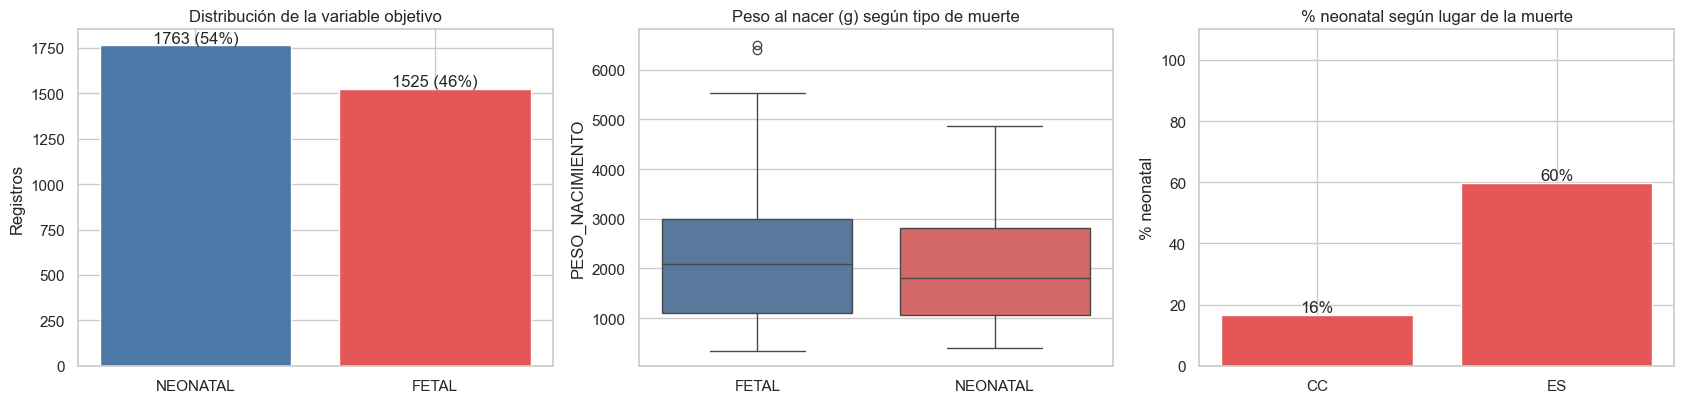

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
nombres = {0: "FETAL", 1: "NEONATAL"}; cols2 = ["#4C78A8", "#E45756"]

cnt = df["y"].map(nombres).value_counts()
ax[0].bar(cnt.index, cnt.values, color=cols2)
for i, v in enumerate(cnt.values):
    ax[0].text(i, v + 12, f"{v} ({v/len(df):.0%})", ha="center")
ax[0].set_title("Distribución de la variable objetivo"); ax[0].set_ylabel("Registros")

sns.boxplot(data=df, x="y", y="PESO_NACIMIENTO", ax=ax[1], palette=cols2)
ax[1].set_xticklabels(["FETAL", "NEONATAL"]); ax[1].set_xlabel("")
ax[1].set_title("Peso al nacer (g) según tipo de muerte")

t = df.groupby("LUGAR_MUERTE")["y"].mean() * 100
ax[2].bar(t.index, t.values, color="#E45756")
for i, v in enumerate(t.values):
    ax[2].text(i, v + 1, f"{v:.0f}%", ha="center")
ax[2].set_ylim(0, 110); ax[2].set_title("% neonatal según lugar de la muerte"); ax[2].set_ylabel("% neonatal")
plt.tight_layout(); plt.show()

## 3. Separar entrenamiento y prueba **antes** de ajustar transformaciones

División **80 % / 20 % estratificada** (conserva la proporción de clases). Imputación, escalado y codificación viven dentro de un `Pipeline` y **solo se ajustan con el entrenamiento**; el conjunto de prueba solo se transforma. Así no hay fuga de información.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Entrenamiento: {X_train.shape[0]} | Prueba: {X_test.shape[0]}")
print("Proporción NEONATAL -> train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

# Transformaciones (se ajustan SOLO con X_train cuando se llama a fit del pipeline)
num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("sc", StandardScaler())])
cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                     ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=15, sparse_output=False))])
prep = ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])

Entrenamiento: 2630 | Prueba: 658
Proporción NEONATAL -> train: 0.536 | test: 0.536


## 4. Entrenamiento de los cinco modelos

Cada modelo se afina con `GridSearchCV` (validación cruzada estratificada de 5 folds **solo sobre el entrenamiento**), optimizando **F1** de la clase positiva (NEONATAL). Las clases están casi equilibradas (≈ 54 % / 46 %), pero se usa F1 y AUC además de la exactitud. Se usa `class_weight="balanced"` donde el modelo lo permite (KNN no lo tiene).

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

modelos = {
    "Regresión logística": (
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
        {"clf__C": [0.01, 0.1, 1, 10]}),
    "Árbol de decisión": (
        DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        {"clf__max_depth": [3, 5, 8, None], "clf__min_samples_leaf": [5, 20, 50]}),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [6, 12, None], "clf__min_samples_leaf": [2, 10]}),
    "KNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 11, 21, 41], "clf__weights": ["uniform", "distance"]}),
    "SVM (RBF)": (
        SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=SEED),
        {"clf__C": [0.5, 1, 5, 20], "clf__gamma": ["scale", 0.01, 0.05]}),
}

fitted, filas = {}, []
for nombre, (est, grid) in modelos.items():
    pipe = Pipeline([("prep", prep), ("clf", est)])
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    t0 = time.time(); gs.fit(X_train, y_train); t_fit = time.time() - t0
    best = gs.best_estimator_
    fitted[nombre] = best

    # F1 en validación cruzada con los mejores hiperparámetros (media y desviación)
    f1_cv = cross_val_score(best, X_train, y_train, scoring="f1", cv=cv, n_jobs=-1)

    t0 = time.time(); pred = best.predict(X_test); t_pred = time.time() - t0
    proba = best.predict_proba(X_test)[:, 1]
    filas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "AUC-ROC": roc_auc_score(y_test, proba),
        "AUC-PR": average_precision_score(y_test, proba),
        "F1 CV (media)": f1_cv.mean(),
        "F1 CV (desv.)": f1_cv.std(),
        "Tiempo ajuste (s)": t_fit,
        "Mejores parámetros": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
    })
    print(f"{nombre:22s} F1 CV={f1_cv.mean():.3f}±{f1_cv.std():.3f} | F1 prueba={filas[-1]['F1']:.3f} | {gs.best_params_}")

res = pd.DataFrame(filas).set_index("Modelo")

Regresión logística    F1 CV=0.716±0.012 | F1 prueba=0.701 | {'clf__C': 10}
Árbol de decisión      F1 CV=0.717±0.011 | F1 prueba=0.688 | {'clf__max_depth': 3, 'clf__min_samples_leaf': 5}
Random Forest          F1 CV=0.714±0.011 | F1 prueba=0.713 | {'clf__max_depth': 12, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 400}
KNN                    F1 CV=0.717±0.009 | F1 prueba=0.741 | {'clf__n_neighbors': 41, 'clf__weights': 'distance'}
SVM (RBF)              F1 CV=0.720±0.010 | F1 prueba=0.696 | {'clf__C': 20, 'clf__gamma': 0.01}


## 5. Tabla comparativa

In [7]:
cols = ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC", "AUC-PR", "F1 CV (media)", "F1 CV (desv.)", "Tiempo ajuste (s)"]
tabla = res[cols].sort_values("F1", ascending=False)
display(tabla.style.format("{:.3f}").background_gradient(cmap="YlGn", subset=["Accuracy","Precision","Recall","F1","AUC-ROC","AUC-PR","F1 CV (media)"])
        .background_gradient(cmap="YlOrRd_r", subset=["F1 CV (desv.)"]).set_caption("Métricas en el conjunto de PRUEBA (CV sobre entrenamiento)"))
print("\nMejores hiperparámetros:")
for m, p in res["Mejores parámetros"].items():
    print(f"  {m:22s} {p}")
tabla.round(4).to_csv("tabla_comparativa.csv")

,Accuracy,Precision,Recall,F1,AUC-ROC,AUC-PR,F1 CV (media),F1 CV (desv.),Tiempo ajuste (s)
Modelo,,,,,,,,,
KNN,0.688,0.668,0.833,0.741,0.749,0.759,0.717,0.009,1.007
Random Forest,0.681,0.689,0.739,0.713,0.765,0.779,0.714,0.011,24.951
Regresión logística,0.658,0.660,0.748,0.701,0.716,0.731,0.716,0.012,11.781
SVM (RBF),0.658,0.665,0.731,0.696,0.733,0.757,0.720,0.010,31.404
Árbol de decisión,0.653,0.666,0.711,0.688,0.705,0.688,0.717,0.011,1.048



Mejores hiperparámetros:
  Regresión logística    {'C': 10}
  Árbol de decisión      {'max_depth': 3, 'min_samples_leaf': 5}
  Random Forest          {'max_depth': 12, 'min_samples_leaf': 2, 'n_estimators': 400}
  KNN                    {'n_neighbors': 41, 'weights': 'distance'}
  SVM (RBF)              {'C': 20, 'gamma': 0.01}


## 6. Gráficos comparativos

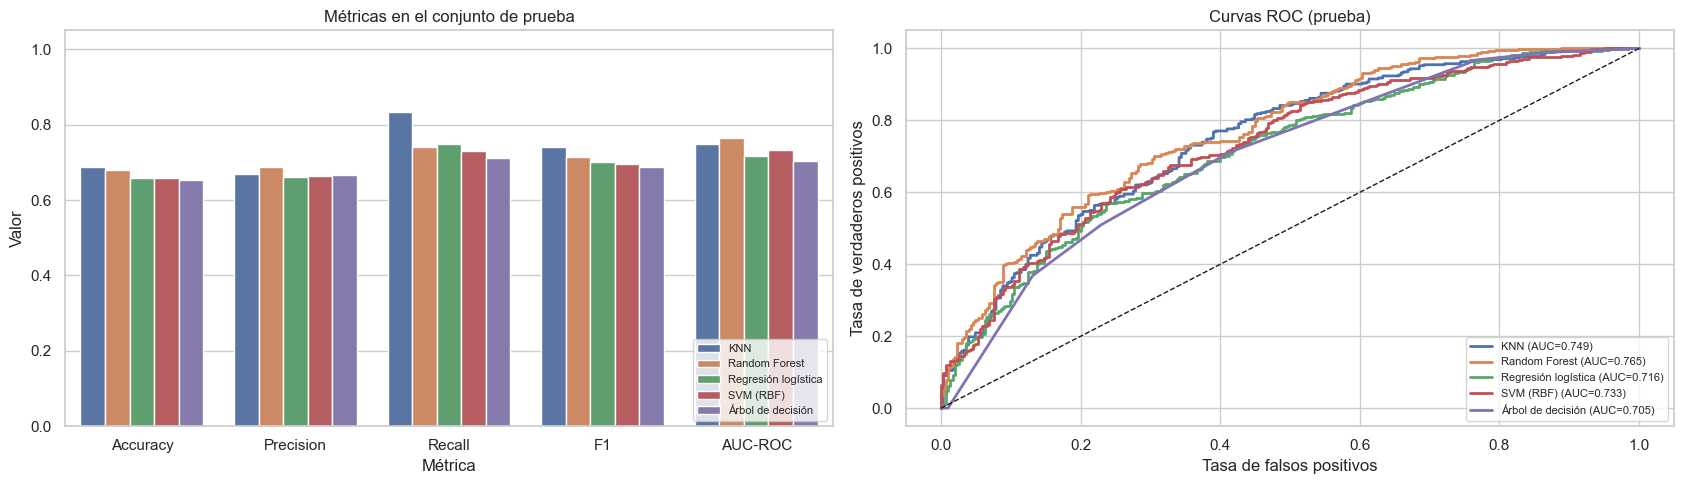

In [8]:
orden = tabla.index.tolist()
paleta = dict(zip(orden, sns.color_palette("deep", len(orden))))

fig, ax = plt.subplots(1, 2, figsize=(17, 5))

# (a) métricas de prueba
m = tabla[["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]].reset_index().melt(id_vars="Modelo", var_name="Métrica", value_name="Valor")
sns.barplot(data=m, x="Métrica", y="Valor", hue="Modelo", hue_order=orden, palette=paleta, ax=ax[0])
ax[0].set_ylim(0, 1.05); ax[0].set_title("Métricas en el conjunto de prueba"); ax[0].legend(fontsize=8, loc="lower right")

# (b) curvas ROC
for nombre in orden:
    p = fitted[nombre].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[1].plot(fpr, tpr, lw=2, color=paleta[nombre], label=f"{nombre} (AUC={roc_auc_score(y_test, p):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_xlabel("Tasa de falsos positivos"); ax[1].set_ylabel("Tasa de verdaderos positivos")
ax[1].set_title("Curvas ROC (prueba)"); ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

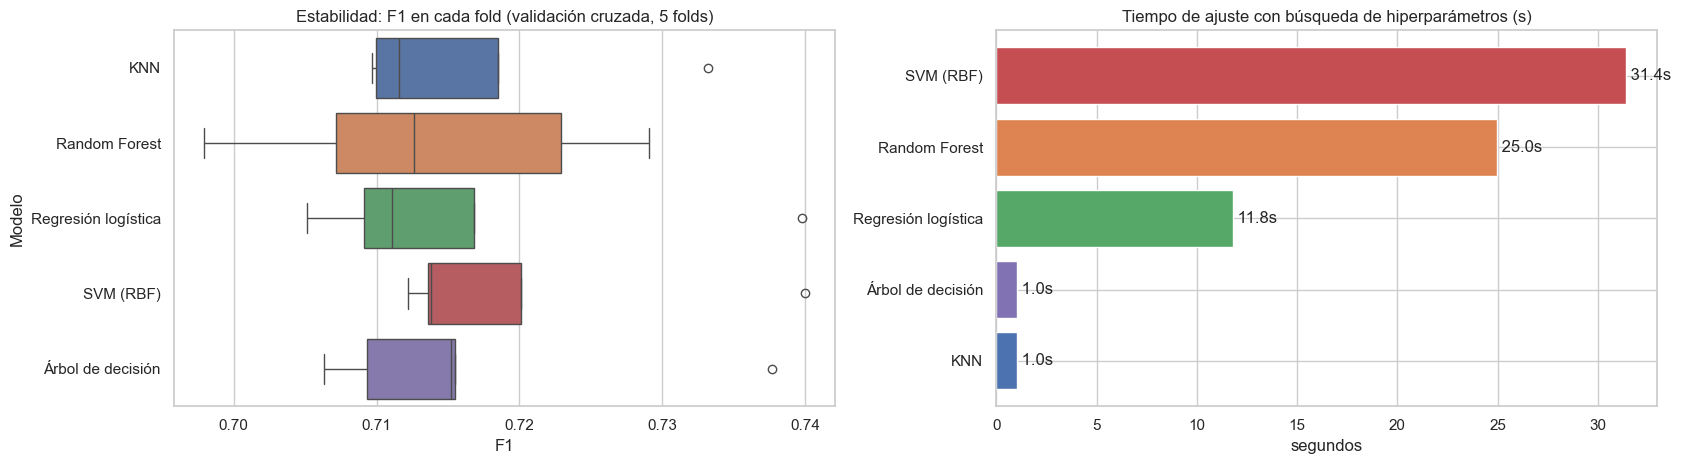

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.8))

# (a) estabilidad: F1 por fold (CV sobre entrenamiento)
datos_cv = []
for nombre in orden:
    s = cross_val_score(fitted[nombre], X_train, y_train, scoring="f1", cv=cv, n_jobs=-1)
    datos_cv += [{"Modelo": nombre, "F1": v} for v in s]
sns.boxplot(data=pd.DataFrame(datos_cv), x="F1", y="Modelo", order=orden, palette=paleta, ax=ax[0])
ax[0].set_title("Estabilidad: F1 en cada fold (validación cruzada, 5 folds)")

# (b) costo computacional
t = tabla["Tiempo ajuste (s)"].sort_values()
ax[1].barh(t.index, t.values, color=[paleta[i] for i in t.index])
for i, v in enumerate(t.values):
    ax[1].text(v, i, f" {v:.1f}s", va="center")
ax[1].set_title("Tiempo de ajuste con búsqueda de hiperparámetros (s)"); ax[1].set_xlabel("segundos")
plt.tight_layout(); plt.show()

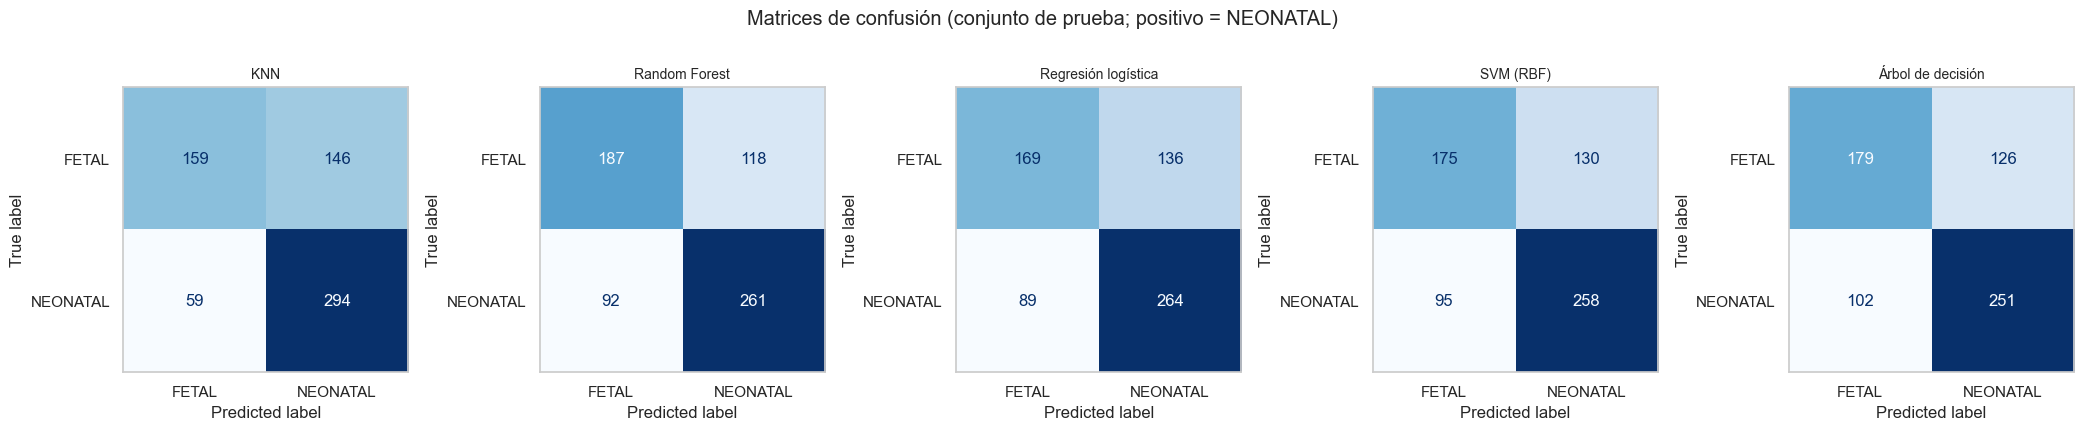

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(21, 4))
for a, nombre in zip(axes, orden):
    pred = fitted[nombre].predict(X_test)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["FETAL", "NEONATAL"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(nombre, fontsize=10); a.grid(False)
plt.suptitle("Matrices de confusión (conjunto de prueba; positivo = NEONATAL)", y=1.04)
plt.tight_layout(); plt.show()

### Variables más importantes (Random Forest y Regresión logística)

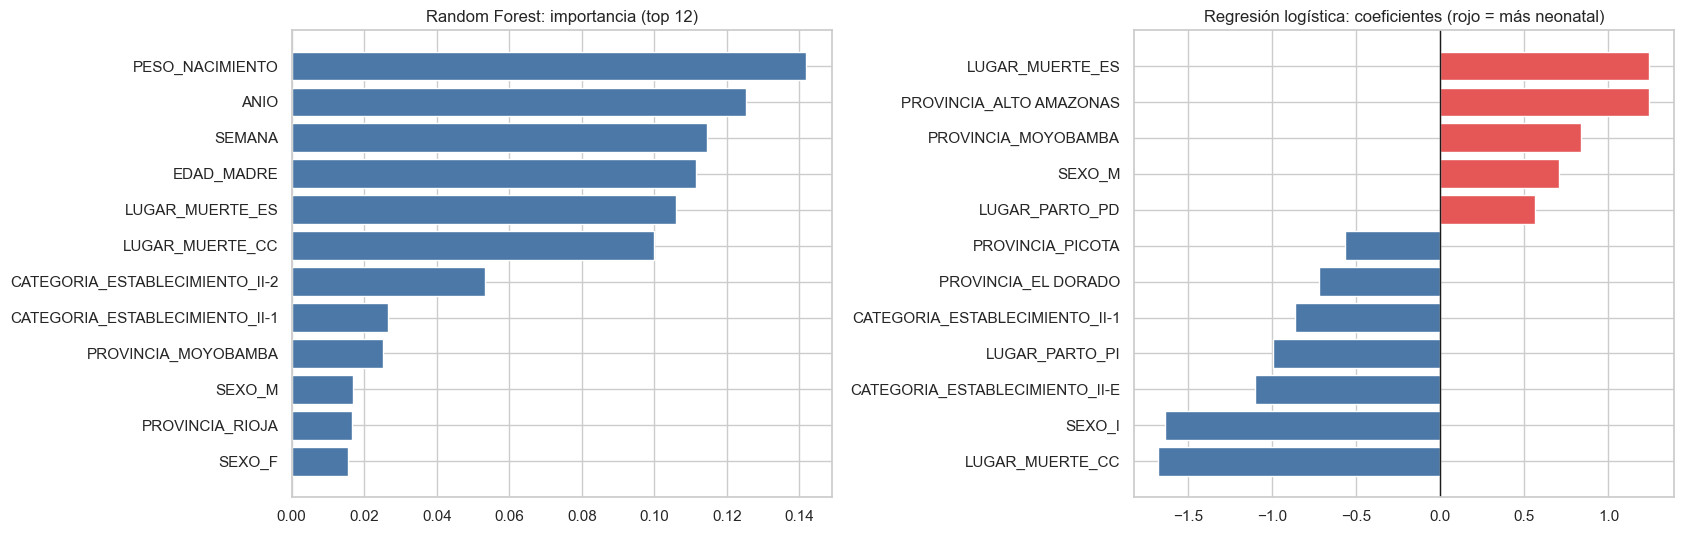

In [11]:
def nombres_features(pipe):
    return pipe.named_steps["prep"].get_feature_names_out()

fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))

rf = fitted["Random Forest"]
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=nombres_features(rf)).sort_values().tail(12)
imp.index = [i.replace("num__", "").replace("cat__", "") for i in imp.index]
ax[0].barh(imp.index, imp.values, color="#4C78A8"); ax[0].set_title("Random Forest: importancia (top 12)")

lr = fitted["Regresión logística"]
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=nombres_features(lr))
top = coef.reindex(coef.abs().sort_values().tail(12).index).sort_values()
top.index = [i.replace("num__", "").replace("cat__", "") for i in top.index]
ax[1].barh(top.index, top.values, color=["#E45756" if v > 0 else "#4C78A8" for v in top.values])
ax[1].axvline(0, color="k", lw=1); ax[1].set_title("Regresión logística: coeficientes (rojo = más neonatal)")
plt.tight_layout(); plt.show()

## 7. Comprobación de fuga de datos (por qué se excluyeron ciertas columnas)

Se entrena el mismo Random Forest **sin** y **con** las columnas que delatan la etiqueta (`PREMATURO`, `MOMENTO`, `ESTANCIA`).

In [12]:
def probar(num_extra, cat_extra):
    nums, cats = num_cols + num_extra, cat_cols + cat_extra
    Xf = df[nums + cats].replace("NO REGISTRADO", np.nan)
    a, b, c, d = train_test_split(Xf, y, test_size=0.20, stratify=y, random_state=SEED)
    pn = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    pp = ColumnTransformer([("num", pn, nums), ("cat", cat_pipe, cats)])
    m = Pipeline([("prep", pp), ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1))]).fit(a, c)
    return accuracy_score(d, m.predict(b)), f1_score(d, m.predict(b)), roc_auc_score(d, m.predict_proba(b)[:, 1])

r1 = probar([], [])
r2 = probar(["MOMENTO", "ESTANCIA"], ["PREMATURO"])
fuga = pd.DataFrame([r1, r2], columns=["Accuracy", "F1", "AUC-ROC"], index=["Sin fuga (usado)", "Con PREMATURO + MOMENTO + ESTANCIA (fuga)"])
display(fuga.style.format("{:.3f}"))

,Accuracy,F1,AUC-ROC
Sin fuga (usado),0.685,0.721,0.757
Con PREMATURO + MOMENTO + ESTANCIA (fuga),0.998,0.999,1.000


## 8. Justificación del mejor modelo

**Criterio (definido sin mirar la prueba):**
1. Se parte del F1 en validación cruzada (5 folds, solo entrenamiento).
2. Los modelos cuya media queda a menos de **una desviación estándar** del mejor se consideran **empatados** (la diferencia es ruido de muestreo).
3. Entre los empatados se elige el de **menor costo computacional** (y, si hay igualdad, el más estable).
4. El conjunto de prueba se usa solo para **confirmar** la elección.

In [13]:
rank = res[["F1 CV (media)", "F1 CV (desv.)", "F1", "AUC-ROC", "Recall", "Tiempo ajuste (s)"]].sort_values("F1 CV (media)", ascending=False)
display(rank.style.format("{:.3f}").set_caption("Ranking por F1 en validación cruzada"))

lider = rank.index[0]
tolerancia = rank.loc[lider, "F1 CV (desv.)"]
empatados = rank[rank["F1 CV (media)"] >= rank.loc[lider, "F1 CV (media)"] - tolerancia]
mejor = empatados.sort_values(["Tiempo ajuste (s)", "F1 CV (desv.)"]).index[0]

print(f"Líder en F1 CV: {lider} | tolerancia (1 desv.): {tolerancia:.3f}")
print("Empatados:", list(empatados.index))
print(f"Modelo elegido (menor costo entre empatados): {mejor}")
r = res.loc[mejor]
print(f"En prueba: F1={r['F1']:.3f} | Recall={r['Recall']:.3f} | Precision={r['Precision']:.3f} | AUC-ROC={r['AUC-ROC']:.3f} | Accuracy={r['Accuracy']:.3f}")

,F1 CV (media),F1 CV (desv.),F1,AUC-ROC,Recall,Tiempo ajuste (s)
Modelo,,,,,,
SVM (RBF),0.720,0.010,0.696,0.733,0.731,31.404
Árbol de decisión,0.717,0.011,0.688,0.705,0.711,1.048
KNN,0.717,0.009,0.741,0.749,0.833,1.007
Regresión logística,0.716,0.012,0.701,0.716,0.748,11.781
Random Forest,0.714,0.011,0.713,0.765,0.739,24.951


Líder en F1 CV: SVM (RBF) | tolerancia (1 desv.): 0.010
Empatados: ['SVM (RBF)', 'Árbol de decisión', 'KNN', 'Regresión logística', 'Random Forest']
Modelo elegido (menor costo entre empatados): KNN
En prueba: F1=0.741 | Recall=0.833 | Precision=0.668 | AUC-ROC=0.749 | Accuracy=0.688


In [14]:
from IPython.display import Markdown
t = tabla
pos_f1 = int(t["F1"].rank(ascending=False)[mejor]); pos_auc = int(t["AUC-ROC"].rank(ascending=False)[mejor])
rapido = t["Tiempo ajuste (s)"].idxmin(); estable = res["F1 CV (desv.)"].idxmin()
empate = len(empatados) > 1
txt = f"""
**Mejor modelo: {mejor}.**

- **Rendimiento en validación cruzada:** F1 = {res.loc[mejor,'F1 CV (media)']:.3f} ± {res.loc[mejor,'F1 CV (desv.)']:.3f}. {'Está empatado con ' + ', '.join(m for m in empatados.index if m != mejor) + f' (todos a menos de una desviación de {lider}, el líder con {rank.loc[lider,chr(70)+chr(49)+chr(32)+chr(67)+chr(86)+chr(32)+chr(40)+chr(109)+chr(101)+chr(100)+chr(105)+chr(97)+chr(41)]:.3f}).' if empate else 'Es el de mayor F1 en validación cruzada.'}
- **Confirmación en prueba ({len(y_test)} registros no vistos):** F1 = {r['F1']:.3f} (puesto {pos_f1} de 5), AUC-ROC = {r['AUC-ROC']:.3f} (puesto {pos_auc} de 5), Recall = {r['Recall']:.3f}, Accuracy = {r['Accuracy']:.3f}.
- **Estabilidad:** desviación del F1 entre folds = {r['F1 CV (desv.)']:.3f} (la más estable es {estable}, con {res['F1 CV (desv.)'].min():.3f}).
- **Costo:** tiempo de ajuste con búsqueda de hiperparámetros = {r['Tiempo ajuste (s)']:.1f} s (el más rápido es {rapido}, con {t['Tiempo ajuste (s)'].min():.1f} s).

**Cómo leer los resultados.** {'Las diferencias de rendimiento entre los modelos empatados no son estadísticamente concluyentes, así que la decisión se apoya en el costo computacional y la estabilidad, y la prueba confirma que no se pierde rendimiento.' if empate else 'La ventaja del modelo elegido es mayor que la variación entre folds.'} Los resultados son moderados (no cercanos a 100 %) porque se excluyeron las columnas que delatan la etiqueta (sección 7); un resultado casi perfecto aquí habría sido señal de fuga de datos.

**Limitaciones.** Una sola región y una sola partición de prueba (la validación cruzada ayuda a medir la variabilidad); `EDAD_MADRE` parece ser en realidad edad gestacional; los datos son sensibles y no deben publicarse caso por caso.
"""
display(Markdown(txt))


**Mejor modelo: KNN.**

- **Rendimiento en validación cruzada:** F1 = 0.717 ± 0.009. Está empatado con SVM (RBF), Árbol de decisión, Regresión logística, Random Forest (todos a menos de una desviación de SVM (RBF), el líder con 0.720).
- **Confirmación en prueba (658 registros no vistos):** F1 = 0.741 (puesto 1 de 5), AUC-ROC = 0.749 (puesto 2 de 5), Recall = 0.833, Accuracy = 0.688.
- **Estabilidad:** desviación del F1 entre folds = 0.009 (la más estable es KNN, con 0.009).
- **Costo:** tiempo de ajuste con búsqueda de hiperparámetros = 1.0 s (el más rápido es KNN, con 1.0 s).

**Cómo leer los resultados.** Las diferencias de rendimiento entre los modelos empatados no son estadísticamente concluyentes, así que la decisión se apoya en el costo computacional y la estabilidad, y la prueba confirma que no se pierde rendimiento. Los resultados son moderados (no cercanos a 100 %) porque se excluyeron las columnas que delatan la etiqueta (sección 7); un resultado casi perfecto aquí habría sido señal de fuga de datos.

**Limitaciones.** Una sola región y una sola partición de prueba (la validación cruzada ayuda a medir la variabilidad); `EDAD_MADRE` parece ser en realidad edad gestacional; los datos son sensibles y no deben publicarse caso por caso.
